In [15]:
from faker import Faker
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import math  
from scipy.optimize import root_scalar

Для расчета вероятности успешного выполнения задания отдельным учеником воспользуемся моделью Раша + добавим коэффициент случайной ошибки.

![Снимок экрана 2026-11-05 022344.png](<attachment:Снимок экрана 2026-11-05 022344.png>)

где Тета i - уровень участника - будем задвать в соответствии с распределением Гаусса
b - сложность задания. будем задавать опираясь на средний процент выполнения задания в 24-26 годах

![Снимок экрана 2026-11-05 022709.png](<attachment:Снимок экрана 2026-11-05 022709.png>)

s - коэффициент случайной ошибки. возьмем примерно 0.95-0.98
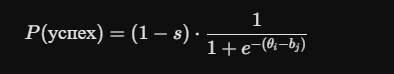
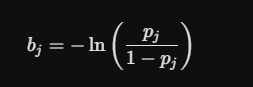

In [16]:
TASK_COMPLETION_RATE_AVG = (
    85.67, 90.53, 70.27, 94.07, 71.8, 95.7, 
    75.37, 71.4, 77.53, 75.9, 81.73, 75.27
)
TASK_COMPLETION_RATE_2026 = (
    92.4, 92.5, 73.2, 94.5, 77.6, 95.5, 82.7, 77.4, 80.7, 78.4, 86.1, 76.7
)

TASK_COMPLETION_RATE_2025 = (
    82.4, 84.9, 69.9, 92.8, 72.6, 97.1, 59.0, 61.2, 68.5, 75.5, 84.7, 69.6
)

TASK_COMPLETION_RATE_2024 = (
    82.2, 94.2, 67.7, 94.9, 65.2, 94.5, 84.4, 75.6, 83.4, 73.8, 74.4, 79.5
)

s = 0.99
k = 1.235
#k где т 1.289 - 1.2905(последнее посчитано по авг)
def calculate_stat(TASK_COMPLETION_RATE):
    TASK_COMPLETION_PERCENTAGE = tuple(x/100 for x in TASK_COMPLETION_RATE)


    def calculate_difficulty(a):
        return -math.log(a/(1-a))

    TASK_DIFFICULTY = tuple(k * calculate_difficulty(x) for x in TASK_COMPLETION_PERCENTAGE)

    beta = np.array(TASK_DIFFICULTY).reshape(1, -1)

    N = 500000  
    theta = np.random.normal(loc=0.0, scale=1.0, size=(N, 1))


    probabilities = s / (1.0 + np.exp(-(theta - beta)))


    return (np.random.rand(N, 12) < probabilities).astype(int)

scores_avg = calculate_stat(TASK_COMPLETION_RATE_AVG)
scores_2026 = calculate_stat(TASK_COMPLETION_RATE_2026)
scores_2025 = calculate_stat(TASK_COMPLETION_RATE_2025)
scores_2024 = calculate_stat(TASK_COMPLETION_RATE_2024)

In [17]:
def make_graph(scores, data):
    # 1. Суммарный первичный балл каждого участника (сумма по строкам матрицы)
    total_scores = scores.sum(axis=1)

    # 2. Фактический процент решаемости каждого задания (среднее по столбцам)
    task_rates = scores.mean(axis=0) * 100

    fig, axes = plt.subplots(1, 2, figsize=(15, 5))

        # График 1: Распределение первичных баллов
    bins = np.arange(14) - 0.5
    axes[0].hist(
        total_scores,
        bins=bins,
        rwidth=0.8,
        color="#4C72B0",
        edgecolor="black",
        density=True,
    )
    axes[0].set_xticks(range(13))
    axes[0].set_title("Распределение суммарных баллов (0–12) " + str(data))
    axes[0].set_xlabel("Первичный балл")
    axes[0].set_ylabel("Плотность (доля участников)")
    axes[0].grid(axis="y", linestyle="--", alpha=0.7)

    # График 2: Процент решаемости заданий №1–12
    task_labels = [f"№{i}" for i in range(1, 13)]
    axes[1].bar(task_labels, task_rates, color="#55A868", edgecolor="black")
    axes[1].set_ylim(0, 100)
    axes[1].set_title("Фактическая решаемость заданий первой части " + str(data))
    axes[1].set_xlabel("Номер задания")
    axes[1].set_ylabel("Процент верных ответов (%)")
    axes[1].grid(axis="y", linestyle="--", alpha=0.7)

    # Подписи процентов над столбцами
    for i, v in enumerate(task_rates):
        axes[1].text(i, v + 1.5, f"{v:.1f}%", ha="center", fontsize=9)

    plt.tight_layout()
    plt.show()

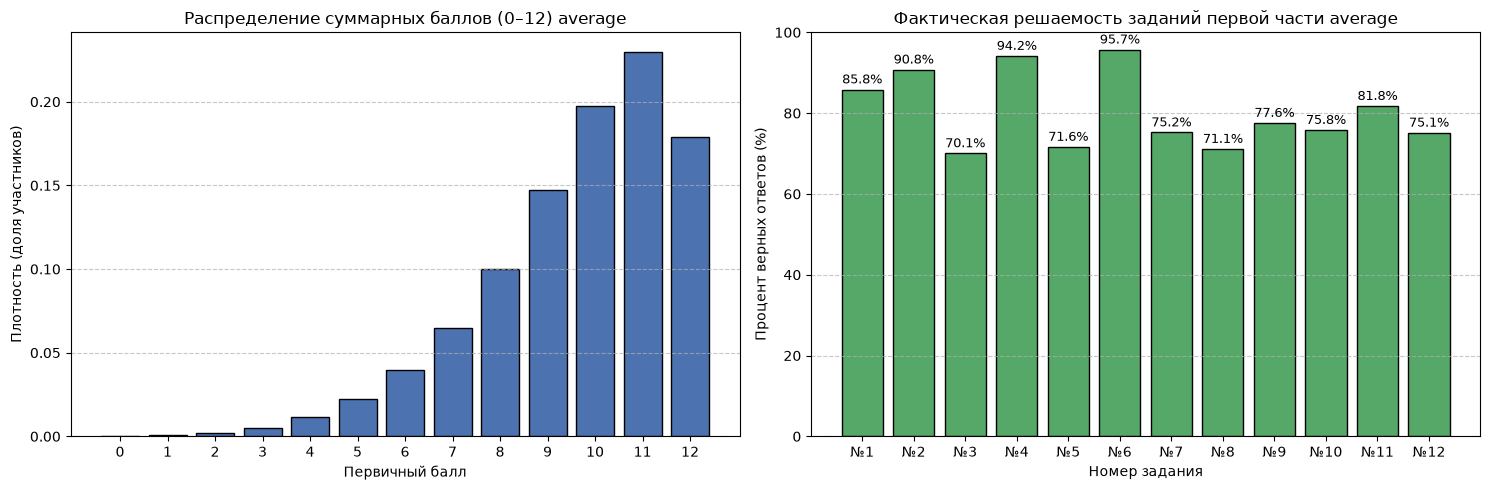

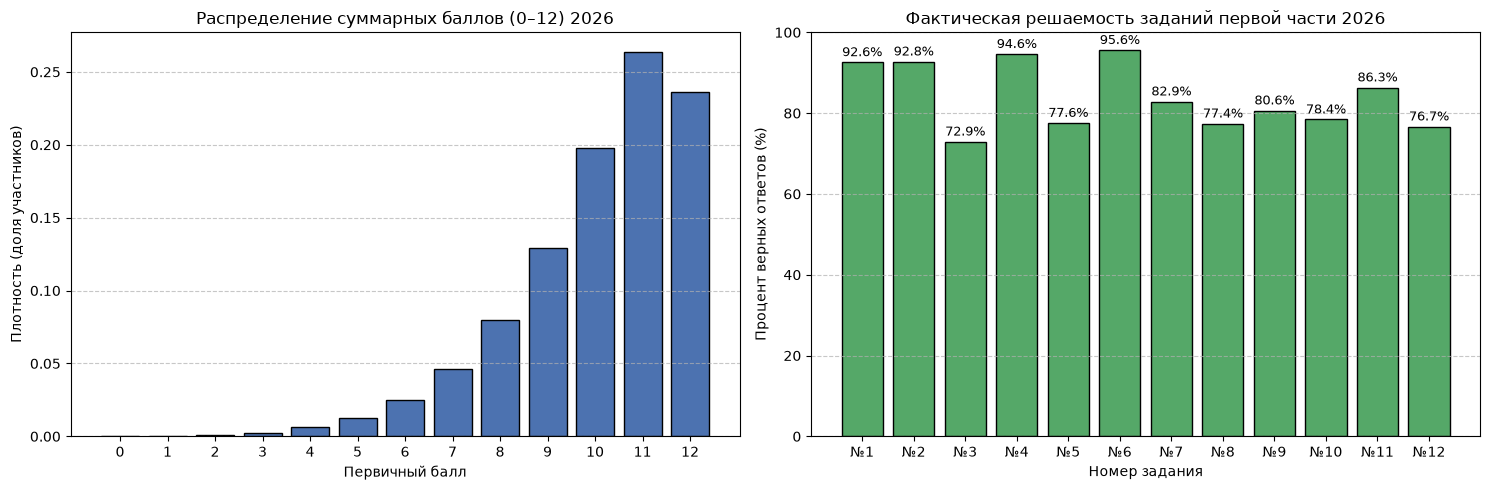

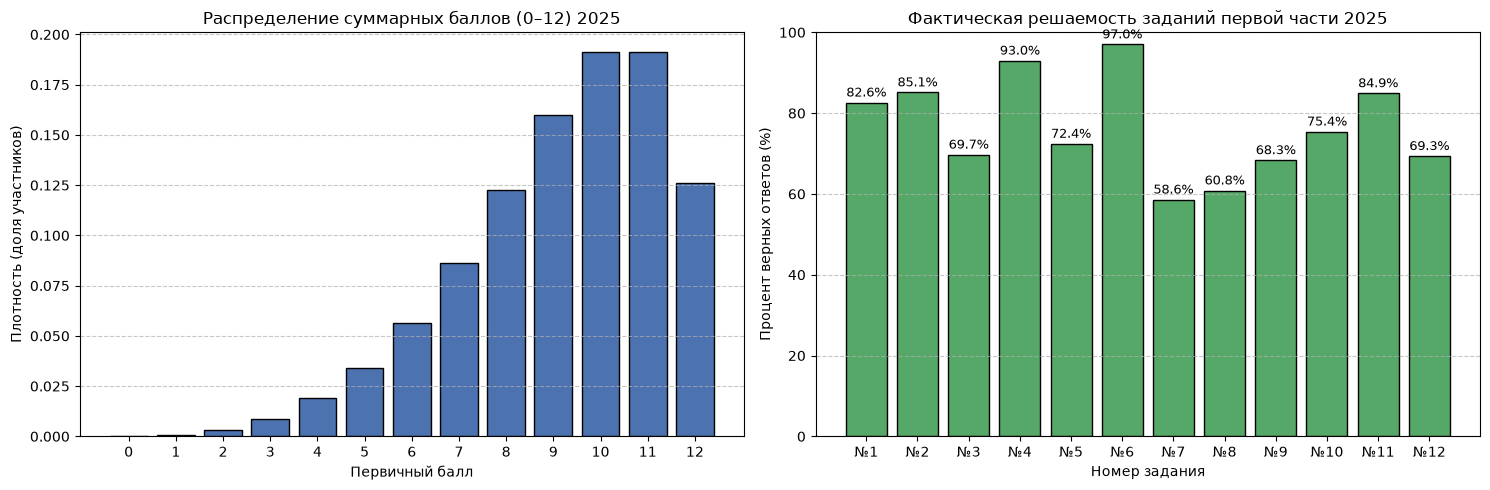

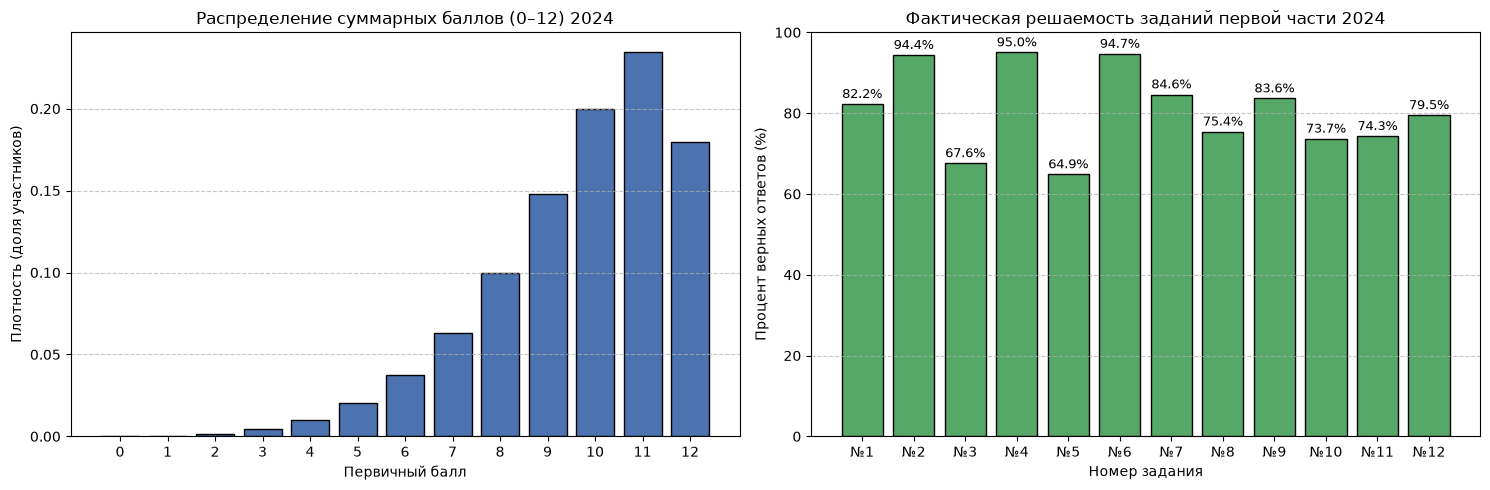

In [18]:
make_graph(scores_avg, 'average')
make_graph(scores_2026, 2026)
make_graph(scores_2025, 2025)
make_graph(scores_2024, 2024)

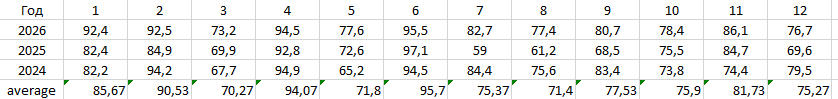

Видим, что сгенерированная статистика по решаемости задний занижена относительно исходных данных ~ на 5 процентов. Это вызывается особенностями нашей матмодели, результат работы которой строго ограничен сверху исходными данными. Соответственно введем некий коэффициент в формуле сложности бета


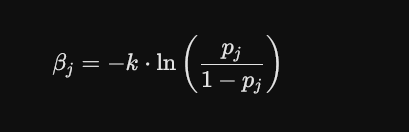

In [19]:
# res = np.array([])
# for i in range (10):
#     theta_sample = np.random.normal(0, 1, size=500000)

#     TASK_COMPLETION_PERCENTAGE_AVG = tuple(x / 100 for x in TASK_COMPLETION_RATE_AVG)
#     TASK_COMPLETION_PERCENTAGE_2026 = tuple(x / 100 for x in TASK_COMPLETION_RATE_2026)
#     TASK_COMPLETION_PERCENTAGE_2025 = tuple(x / 100 for x in TASK_COMPLETION_RATE_2025)
#     TASK_COMPLETION_PERCENTAGE_2024 = tuple(x / 100 for x in TASK_COMPLETION_RATE_2024)


#     p_targets = np.array(TASK_COMPLETION_PERCENTAGE_AVG)

#     base_logits = -np.log(p_targets / (1.0 - p_targets))


#     def loss_k(k):
#         beta_scaled = (base_logits * k).reshape(1, -1)

#         p_sim = s / (1.0 + np.exp(-(theta_sample.reshape(-1, 1) - beta_scaled)))

#         return (p_sim.mean(axis=0) - p_targets).mean()


#     res_k = root_scalar(loss_k, bracket=[0.8, 2.0], method="brentq")
#     K_FACTOR = res_k.root

#    # print(f"Искомый множитель k = {K_FACTOR:.4f}")
#     res = np.append(res, K_FACTOR)

# print (np.mean(res))
# #соответственно, получаем при авг значения ~1.289, а если взять среднее по всем - 1.2905

Раньше в егэ (начало двухтысячных) использовалась однопараметрическая модель Раша. но чето не так с ней было, типа шкала скакала. Так что сейчас другая, но мы сделаем по рашу тк у меня такой вайб и ее можно объяснить. +для тестовой части она вроде норм работает


In [21]:
def calculate_difficulty(a):
        return -math.log(a/(1-a))

def build_primary_to_secondary_scale(
    TASK_COMPLETION_RATE,
    k_val=k,
    s_val=s,
    secondary_max=70,
    n_groups=4001
):
    # 1. Считаем трудности 12 заданий beta точ-в-точь как в твоей функции calculate_stat
    TASK_COMPLETION_PERCENTAGE = tuple(x / 100 for x in TASK_COMPLETION_RATE)
    TASK_DIFFICULTY = tuple(k_val * calculate_difficulty(x) for x in TASK_COMPLETION_PERCENTAGE)
    beta = np.array(TASK_DIFFICULTY).reshape(1, -1)  # размер (1, 12)

    # 2. Разбиваем учеников на группы по уровню подготовки theta от -6 до +6
    theta_grid = np.linspace(-6.0, 6.0, n_groups).reshape(-1, 1)  # размер (4001, 1)

    # Считаем долю каждой группы в популяции по обычной формуле колокола Гаусса N(0, 1)
    weights = np.exp(-0.5 * (theta_grid ** 2)) / np.sqrt(2.0 * np.pi)
    weights = weights / weights.sum()  # нормируем, чтобы сумма долей всех групп равнялась строго 1

    # 3. Вероятность решения каждого из 12 заданий для каждой группы (твоя формула Раша)
    # Матрица task_probs имеет размер (4001 группа, 12 заданий)
    task_probs = s_val / (1.0 + np.exp(-(theta_grid - beta)))

    # 4. Считаем шанс набрать сумму r баллов (от 0 до 12) для каждой группы theta
    # score_probs[m, r] — вероятность того, что группа m наберет ровно r первичных баллов
    n_tasks = len(TASK_COMPLETION_RATE)
    score_probs = np.zeros((n_groups, n_tasks + 1))
    score_probs[:, 0] = 1.0  # До старта (0 заданий пройдено) у всех ровно 0 баллов с шансом 100%

    for i in range(n_tasks):
        p_i = task_probs[:, i:i + 1]  # шанс решить текущее i-е задание
        next_score_probs = np.zeros_like(score_probs)

        # Вариант А: ученик НЕ решил i-е задание (балл остался прежним)
        next_score_probs[:, :i + 1] = score_probs[:, :i + 1] * (1.0 - p_i)

        # Вариант Б: ученик РЕШИЛ i-е задание (к прошлым баллам прибавилась +1)
        next_score_probs[:, 1:i + 2] += score_probs[:, :i + 1] * p_i

        score_probs = next_score_probs

    # 5. Формула Байеса: взвешиваем шансы набрать балл r на размер каждой группы учеников
    joint_probs = score_probs * weights          # совместная вероятность: P(r | theta) * W(theta)
    prob_of_score = joint_probs.sum(axis=0)      # общая доля людей в стране, набравших ровно r баллов

    # Ожидаемый уровень знаний для каждого балла r (среднее взвешенное theta по группам)
    theta_expected = (joint_probs * theta_grid).sum(axis=0) / prob_of_score

    # 6. Переводим найденный уровень знаний theta в шкалу 0..70 тестовых баллов
    theta_min = theta_expected[0]   # уровень знаний при 0 баллах
    theta_max = theta_expected[-1]  # уровень знаний при 12 баллах

    secondary_exact = secondary_max * (theta_expected - theta_min) / (theta_max - theta_min)
    secondary_integer = np.round(secondary_exact).astype(int)

    scale_df = pd.DataFrame({
        "Первичный балл": np.arange(n_tasks + 1),
        "Ожидаемый уровень (theta)": theta_expected,
        "Вторичный балл (точный)": secondary_exact,
        "Вторичный балл": secondary_integer,
        "Доля участников, %": prob_of_score * 100.0,
    })

    return scale_df


# Строим основную шкалу по средним данным 2024-2026
scale_main = build_primary_to_secondary_scale(TASK_COMPLETION_RATE_AVG)
display(scale_main.round(2))

# # График устойчивости шкалы по годам
# rates_by_period = {
#     "Среднее 2024–2026": TASK_COMPLETION_RATE_AVG,
#     "2024": TASK_COMPLETION_RATE_2024,
#     "2025": TASK_COMPLETION_RATE_2025,
#     "2026": TASK_COMPLETION_RATE_2026,
# }

# plt.figure(figsize=(10, 6))
# for period, rates in rates_by_period.items():
#     df_period = build_primary_to_secondary_scale(rates)
#     plt.plot(
#         df_period["Первичный балл"],
#         df_period["Вторичный балл (точный)"],
#         marker="o",
#         label=period,
#     )

# plt.xticks(range(13))
# plt.yticks(range(0, 71, 5))
# plt.xlabel("Первичный балл")
# plt.ylabel("Вторичный балл")
# plt.title("Сравнение шкал перевода по годам")
# plt.grid(alpha=0.3)
# plt.legend()
# plt.show()

,Первичный балл,Ожидаемый уровень (theta),Вторичный балл (точный),Вторичный балл,"Доля участников, %"
0,0,-3.15,0.00,0,0.01
1,1,-2.81,5.78,6,0.05
2,2,-2.49,11.19,11,0.19
3,3,-2.18,16.36,16,0.52
4,4,-1.89,21.39,21,1.15
5,5,-1.60,26.38,26,2.24
6,6,-1.30,31.42,31,3.95
7,7,-0.99,36.63,37,6.48
8,8,-0.67,42.15,42,10.03
9,9,-0.32,48.12,48,14.65


Для сравнения шкала реального егэ:


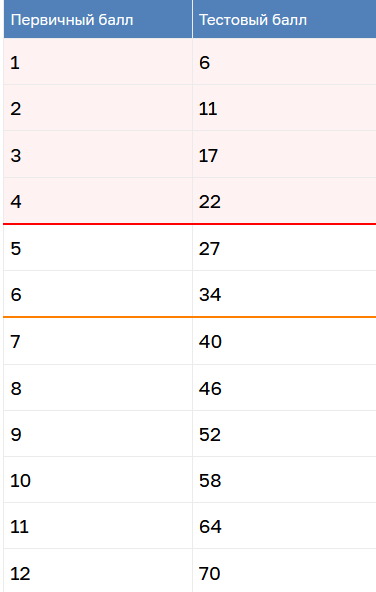

In [23]:
import numpy as np
import pandas as pd


def calculate_psychometrics_tz(scores_matrix):
    """
    Полный психометрический расчёт:
    1. Альфа Кронбаха (внутренняя согласованность теста).
    2. Решаемость p и индекс дифференциации D по методу крайних групп (верхние/нижние 27%)
       с автоматической простановкой флагов по ТЗ (FR-06 / FR-07).
    """
    scores = np.asarray(scores_matrix, dtype=float)
    n_students, n_tasks = scores.shape
    total_scores = scores.sum(axis=1)

    # --- 1. Альфа Кронбаха ---
    var_items = scores.var(axis=0, ddof=1)
    var_total = total_scores.var(ddof=1)
    cronbach_alpha = (n_tasks / (n_tasks - 1)) * (1.0 - var_items.sum() / var_total)

    # --- 2. Решаемость p и дифференциация D (правило 27%) ---
    k_27 = int(np.round(n_students * 0.27))
    sorted_idx = np.argsort(total_scores)

    bottom_27_idx = sorted_idx[:k_27]   # нижние 27% работ по первичному баллу
    top_27_idx = sorted_idx[-k_27:]     # верхние 27% работ по первичному баллу

    p_all = scores.mean(axis=0)
    p_top = scores[top_27_idx].mean(axis=0)
    p_bottom = scores[bottom_27_idx].mean(axis=0)

    d_values = p_top - p_bottom

    # --- 3. Флаги по условиям ТЗ ---
    flags = []
    for d in d_values:
        if d < 0:
            flags.append("отрицательная дифференциация")
        elif d < 0.2:
            flags.append("низкая дифференциация")
        else:
            flags.append("норма")

    report_df = pd.DataFrame({
        "Задание": [f"№{i+1}" for i in range(n_tasks)],
        "p (решаемость)": np.round(p_all, 3),
        "p (верхние 27%)": np.round(p_top, 3),
        "p (нижние 27%)": np.round(p_bottom, 3),
        "D (индекс дифф.)": np.round(d_values, 3),
        "Флаг": flags,
    })

    # Отдельный список заданий с флагами для отчёта
    flagged_tasks_df = report_df[report_df["Флаг"] != "норма"].copy()

    return cronbach_alpha, report_df, flagged_tasks_df


# Запуск расчётов на симулированных данных (Среднее за 2024–2026)
alpha, report_df, flagged_df = calculate_psychometrics_tz(scores_avg)

print("НАДЕЖНОСТЬ ТЕСТА")
print(f"Альфа Кронбаха: {alpha:.3f}")
if alpha >= 0.7:
    print("Статус: Хорошая надежность. Экзамен измеряет единый конструкт.")
else:
    print("Статус: Удовлетворительная/Низкая надежность (типично для первой части ЕГЭ, где разные темы).")

print("\nМЕТРИКИ ЗАДАНИЙ (p и D по правилу 27%):")
display(report_df)

print("\nЗАДАНИЯ С ФЛАГАМИ (отдельный блок отчёта по ТЗ):")
if flagged_df.empty:
    print("Заданий с низкой или отрицательной дифференциацией не обнаружено.")
else:
    display(flagged_df[["Задание", "p (решаемость)", "D (индекс дифф.)", "Флаг"]])

НАДЕЖНОСТЬ ТЕСТА
Альфа Кронбаха: 0.599
Статус: Удовлетворительная/Низкая надежность (типично для первой части ЕГЭ, где разные темы).

МЕТРИКИ ЗАДАНИЙ (p и D по правилу 27%):


,Задание,p (решаемость),p (верхние 27%),p (нижние 27%),D (индекс дифф.),Флаг
0,№1,0.858,0.983,0.670,0.312,норма
1,№2,0.908,0.989,0.780,0.210,норма
2,№3,0.701,0.953,0.398,0.555,норма
3,№4,0.942,0.993,0.860,0.133,низкая дифференциация
4,№5,0.716,0.956,0.419,0.537,норма
5,№6,0.957,0.994,0.899,0.095,низкая дифференциация
6,№7,0.752,0.964,0.476,0.488,норма
7,№8,0.711,0.955,0.413,0.542,норма
8,№9,0.776,0.968,0.514,0.454,норма
9,№10,0.758,0.966,0.484,0.481,норма



ЗАДАНИЯ С ФЛАГАМИ (отдельный блок отчёта по ТЗ):


,Задание,p (решаемость),D (индекс дифф.),Флаг
3,№4,0.942,0.133,низкая дифференциация
5,№6,0.957,0.095,низкая дифференциация


Контроль качества данных и выполнение требований к шкале - монотонность, полнота покрытия, граничные условия


In [ ]:
def validate_data_and_scale(scores_matrix, scale_df):
    assert scores_matrix.ndim == 2 and scores_matrix.shape[1] == 12, "Матрица должна содержать ровно 12 заданий"
    assert not np.isnan(scores_matrix).any(), "Обнаружены пропуски (NaN) в матрице ответов"
    assert np.isin(scores_matrix, [0, 1]).all(), "Матрица ответов должна быть строго бинарной (0 или 1)"

    prim = scale_df["Первичный балл"].to_numpy()
    sec = scale_df["Вторичный балл"].to_numpy()
    theta_eap = scale_df["Ожидаемый уровень (theta)"].to_numpy()

    assert np.array_equal(prim, np.arange(13)), "Неполное покрытие первичных баллов 0..12"
    assert np.all(np.diff(theta_eap) > 0), "Оценки способности EAP должны строго возрастать"
    assert np.all(np.diff(sec) >= 0), "Нарушена монотонность шкалы перевода"
    assert sec[0] == 0 and sec[-1] == 70, "Нарушены граничные условия шкалы (0 -> 0, 12 -> 70)"
    print("[OK] Проверка качества данных (NFR-03) и монотонности шкалы (FR-04, NFR-02) успешно пройдена!")

validate_data_and_scale(scores_avg, scale_main)

Детекция разного вида аномалий, в том числе методом Тьюки

In [ ]:
import json
import hashlib
import uuid

CODEFICATOR_MAP = [
    "5.1.1", "7.1.1", "8.1.1", "8.2.1", "2.1.1", "1.1.1",
    "4.1.1", "7.2.1", "3.1.1", "3.2.1", "4.2.1", "4.3.1"
]

def export_project_json_artifacts(scores_matrix, scale_df, rates_avg=TASK_COMPLETION_RATE_AVG, rates_2025=TASK_COMPLETION_RATE_2025):
    # 1. Шкала перевода (п. 7.2 ТЗ: scale_math_profile_2026.json)
    scale_json = {
        "schemaVersion": "1.0",
        "subject": "math",
        "level": "profile",
        "year": 2026,
        "maxPrimary": 12,
        "minThresholdPrimary": 5,
        "entries": [
            {"primary": int(row["Первичный балл"]), "test": int(row["Вторичный балл"])}
            for _, row in scale_df.iterrows()
        ],
        "note": "Метод: модифицированная модель Раша (1PL IRT с верхней асимптотой s=0.99, k=1.235) + EAP (методика v1.0)"
    }
    with open("scale_math_profile_2026.json", "w", encoding="utf-8") as f:
        json.dump(scale_json, f, ensure_ascii=False, indent=2)

    # 2. Статистика заданий (п. 7.3 ТЗ: task-stats.json)
    alpha, report_df, flagged_df = calculate_psychometrics_tz(scores_matrix)
    n_students = scores_matrix.shape[0]
    correct_counts = scores_matrix.sum(axis=0).astype(int)

    tasks_json = []
    for i, row in report_df.iterrows():
        d_val = float(row["D (индекс дифф.)"])
        p_val = float(row["p (решаемость)"])
        flag_code = "NEGATIVE_DISCRIMINATION" if d_val < 0 else ("LOW_DISCRIMINATION" if d_val < 0.2 else None)
        tasks_json.append({
            "taskId": f"task-{i+1}",
            "codeficator": CODEFICATOR_MAP[i],
            "answered": int(n_students),
            "correct": int(correct_counts[i]),
            "pValue": round(p_val, 3),
            "avgScore": round(p_val, 3),
            "skipRate": 0.0,
            "discrimination": round(d_val, 3),
            "flag": flag_code
        })

    task_stats_json = {
        "sessionId": "2026-06-08-math-prof-01",
        "subject": "math",
        "level": "profile",
        "year": 2026,
        "cronbachAlpha": round(float(alpha), 4),
        "tasks": tasks_json,
        "distractors": []
    }
    with open("task-stats.json", "w", encoding="utf-8") as f:
        json.dump(task_stats_json, f, ensure_ascii=False, indent=2)

    # 3. Детекция аномалий методом Тьюки (п. 7.4 ТЗ: anomalies_cards_2026.json)
    n_check = min(10000, n_students)
    sub_scores = scores_matrix[:n_check]
    prim_sub = sub_scores.sum(axis=1)

    # Оцениваем вероятность каждого ответа через EAP-способность участника
    theta_lookup = scale_df["Ожидаемый уровень (theta)"].to_numpy()
    theta_hat = theta_lookup[prim_sub].reshape(-1, 1)
    beta_vec = np.array([k * calculate_difficulty(x / 100.0) for x in rates_avg]).reshape(1, -1)
    probs_hat = np.clip(s / (1.0 + np.exp(-(theta_hat - beta_vec))), 1e-15, 1.0 - 1e-15)

    ll = np.sum(sub_scores * np.log(probs_hat) + (1.0 - sub_scores) * np.log(1.0 - probs_hat), axis=1)
    q1, q3 = np.percentile(ll, [25, 75])
    iqr = q3 - q1
    lower_fence = q1 - 1.5 * iqr
    anomaly_indices = np.where(ll < lower_fence)[0]

    cards = []
    now_iso = "2026-11-14T09:00:00.000Z"
    for idx in anomaly_indices[:50]:
        pseudo_id = hashlib.sha256(f"salt_2026_student_{idx}".encode()).hexdigest()[:16]
        cards.append({
            "anomalyId": str(uuid.uuid5(uuid.NAMESPACE_DNS, f"work-{pseudo_id}")),
            "createdAt": now_iso,
            "type": "INVERTED_PROFILE",
            "objectKind": "room",
            "objectId": f"participant-{pseudo_id}",
            "metrics": [
                {"name": "log_likelihood", "value": round(float(ll[idx]), 4), "threshold": round(float(lower_fence), 4), "unit": "logit"},
                {"name": "primary_score", "value": int(prim_sub[idx]), "threshold": 5, "unit": "балл"}
            ],
            "severity": "high" if ll[idx] < (q1 - 3.0 * iqr) else "medium",
            "recommendation": "Сигнал для проверки (ДП-05): аномальный профиль ответов по критерию Тьюки, автоматическое изменение баллов не производится",
            "dataWindow": {"from": "2026-06-08T07:00:00.000Z", "to": "2026-06-08T11:00:00.000Z"}
        })

    anomalies_json = {
        "schemaVersion": "1.0",
        "method": "Tukey IQR (Q1 - 1.5*IQR on Log-Likelihood)",
        "totalWorksChecked": int(n_check),
        "tukeyLowerFenceLL": round(float(lower_fence), 4),
        "anomaliesDetectedTotal": int(len(anomaly_indices)),
        "cardsExported": len(cards),
        "cards": cards
    }
    with open("anomalies_cards_2026.json", "w", encoding="utf-8") as f:
        json.dump(anomalies_json, f, ensure_ascii=False, indent=2)

    # 4. Эталонный набор >= 500 пар с контрольной суммой SHA-256 (FR-04, NFR-02)
    sec_lookup = scale_df["Вторичный балл"].to_numpy()
    cases = []
    for idx in range(500):
        pseudo = hashlib.sha256(f"ref_2026_{idx}".encode()).hexdigest()[:16]
        prim = int(scores_matrix[idx].sum())
        cases.append({
            "caseId": idx + 1,
            "participantPseudonym": pseudo,
            "responses": scores_matrix[idx].tolist(),
            "primaryScore": prim,
            "expectedTestScore": int(sec_lookup[prim]),
            "passedMinThreshold": bool(prim >= 5)
        })
    checksum = hashlib.sha256(json.dumps(cases, sort_keys=True).encode("utf-8")).hexdigest()
    ref_json = {
        "schemaVersion": "1.0",
        "subject": "math",
        "level": "profile",
        "year": 2026,
        "count": 500,
        "sha256Checksum": checksum,
        "cases": cases
    }
    with open("reference_dataset_500.json", "w", encoding="utf-8") as f:
        json.dump(ref_json, f, ensure_ascii=False, indent=2)

    print("Сформированы JSON-артефакты для Git:")
    print(f"1. scale_math_profile_2026.json ({len(scale_json['entries'])} записей шкалы 0..12 -> 0..70)")
    print(f"2. task-stats.json (Альфа Кронбаха = {alpha:.3f}, заданий с флагами: {len(flagged_df)})")
    print(f"3. anomalies_cards_2026.json (Проверено работ: {n_check}, найдено аномалий по Тьюки: {len(anomaly_indices)})")
    print(f"4. reference_dataset_500.json (500 эталонных пар, SHA-256: {checksum[:16]}...)")

export_project_json_artifacts(scores_avg, scale_main)